# Thực hành Buổi 31 (Thứ 6 - 13/11): Kiến trúc CNN Hiện đại (Mini-ResNet & Skip Connection) trên Ảnh màu CIFAR-10

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import cifar10

(X_train_full, y_train_full), (X_test_full, y_test_full) = cifar10.load_data()

y_train_full = y_train_full.flatten()
y_test_full = y_test_full.flatten()

class_names =['May bay', 'O to', 'Chim', 'Meo', 'Huou','Cho', 'Ech', 'Ngua','Tau Thuy', 'Xe tai']

print ("Kich thuoc X_train_full:", X_train_full.shape)
print("Kich thuoc X_test_full:", X_test_full.shape)

Kich thuoc X_train_full: (50000, 32, 32, 3)
Kich thuoc X_test_full: (10000, 32, 32, 3)


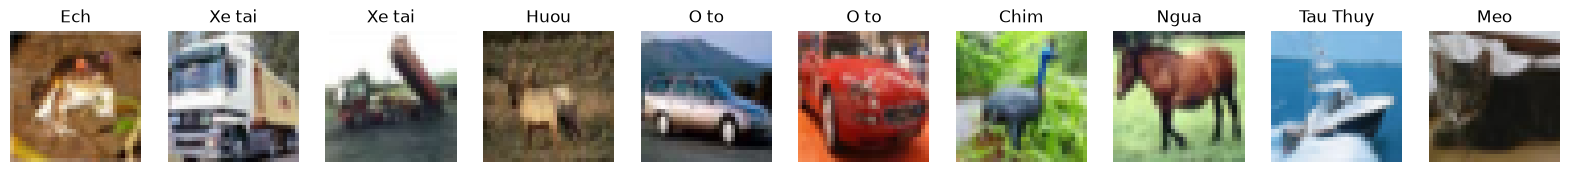

In [4]:
fig, axes = plt.subplots(nrows=1, ncols=10, figsize=(20, 3))
for i in range(10):
    axes[i].imshow(X_train_full[i])
    axes[i].set_title(class_names[y_train_full[i]])
    axes[i].axis('off')
plt.show()

In [5]:
X_train = X_train_full[:10000].astype('float32') / 255.0
y_train = y_train_full[:10000]

X_test = X_test_full[:2000].astype('float32') / 255.0
y_test = y_test_full[:2000]

print(f"X_train: {X_train.shape}, Min: {X_train.min():.1f}, Max: {X_train.max():.1f}")
print(f"X_test: {X_test.shape}, Min: {X_test.min():.1f}, Max: {X_test.max():.1f}")

X_train: (10000, 32, 32, 3), Min: 0.0, Max: 1.0
X_test: (2000, 32, 32, 3), Min: 0.0, Max: 1.0


In [6]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import(
    Input, Conv2D, BatchNormalization, Activation,
    Add, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout
)

inputs = Input(shape=(32, 32, 3))

x = Conv2D(32, (3, 3), padding='same')(inputs)
x = BatchNormalization()(x)
x = Activation('relu')(x)

shortcut = x
x = Conv2D(32, (3, 3), padding='same')(x)
x = BatchNormalization()(x)
x = Activation('relu')(x)
x = Conv2D(32, (3, 3), padding='same')(x)
x = BatchNormalization()(x)
x = Add()([x, shortcut])
x = Activation('relu')(x)
x = MaxPooling2D((2, 2))(x)

shortcut = Conv2D(64, (1, 1), padding='same')(x)
x = Conv2D(64, (3, 3), padding='same')(x)
x = BatchNormalization()(x)
x = Add()([x, shortcut])
x = Activation('relu')(x)
x = MaxPooling2D((2, 2))(x)

x = GlobalAveragePooling2D()(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(10, activation='softmax')(x)

model = Model(inputs=inputs, outputs=outputs, name='Mini_ResNet_CIFAR10')
model.summary()

Model: "Mini_ResNet_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 32,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │      9,248 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 16, 16,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │      2,112 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 16, 16,    │          0 │ add_1[0][0]     

 Total params: 45,450 (177.54 KB)

 Trainable params: 45,130 (176.29 KB)

 Non-trainable params: 320 (1.25 KB)

In [7]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

model.compile(
    optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy']
)
early_stop = EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)
history = model.fit(
    X_train, y_train, epochs=10, batch_size=64, validation_split=0.2, callbacks=[early_stop]
)



Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.2659 - loss: 1.9899 - val_accuracy: 0.1105 - val_loss: 2.6073
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 51ms/step - accuracy: 0.3444 - loss: 1.7460 - val_accuracy: 0.1185 - val_loss: 3.0155
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - accuracy: 0.3955 - loss: 1.6191 - val_accuracy: 0.1540 - val_loss: 2.7040
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 51ms/step - accuracy: 0.4390 - loss: 1.5210 - val_accuracy: 0.2655 - val_loss: 2.3097
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.4664 - loss: 1.4544 - val_accuracy: 0.4320 - val_loss: 1.5671
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - accuracy: 0.4956 - loss: 1.3977 - val_accuracy: 0.3935 - val_loss: 1.5878
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.5094 - loss: 1.3457 - val_accuracy: 0.4015 - val_loss: 1.6087
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.5322 - loss: 1.2965 - val_accu

Do chinh xac ten tap Test (2,000 anh mau): 45.15


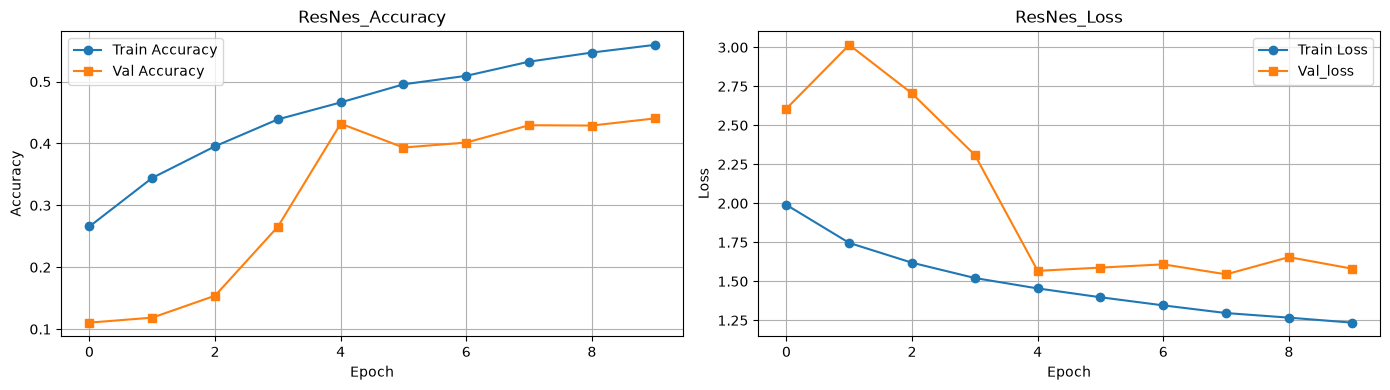

In [8]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Do chinh xac ten tap Test (2,000 anh mau): {test_acc * 100:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history.history['accuracy'], label='Train Accuracy', marker='o')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy', marker='s')
axes[0].set_title('ResNes_Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history['loss'], label='Train Loss', marker='o')
axes[1].plot(history.history['val_loss'], label='Val_loss', marker='s')
axes[1].set_title('ResNes_Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

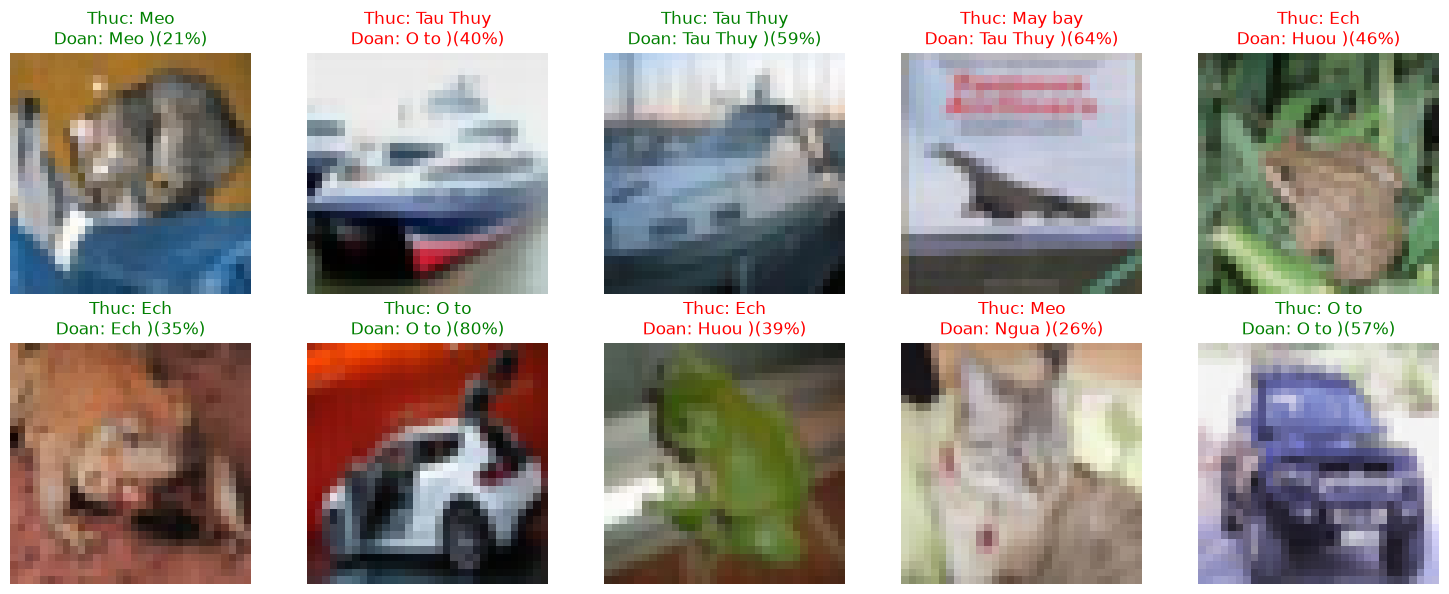

In [14]:
import numpy as np

y_pred_probs = model.predict(X_test[:10], verbose=0)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i in range(10):
    axes[i].imshow(X_test[i])
    true_name = class_names[y_test[i]]
    pred_name = class_names[y_pred_classes[i]]
    conf = np.max(y_pred_probs[i]) * 100

    color = 'green' if y_test[i] == y_pred_classes[i] else 'red'
    axes[i].set_title(f"Thuc: {true_name}\nDoan: {pred_name} )({conf:.0f}%)", color=color)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

